# 01 · Exploring the House races dataset

Before building any models, this notebook checks that the processed data looks right and answers a few questions that shape the modeling choices:

1. **Is the data sane?** Seat counts by party should match the historical record.
2. **How should uncontested races be handled?** They show up as margins of exactly ±1.
3. **How predictable is a district from its last election?** This is the core signal behind `margin_lag1`.
4. **Has that relationship changed over time?** This decides how much the Bayesian models should trust a prior built from 1978–1998.
5. **What do incumbency and the midterm penalty look like in the data?**
6. **How hard is the problem?** Class balance, the share of competitive races, and the naive baseline.

Run `python src/build_dataset.py --input data/raw/<file>` first to create `data/processed/house_races.csv`.

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data/processed/house_races.csv")
FIGS = Path("../results/figures")
FIGS.mkdir(parents=True, exist_ok=True)

if not DATA.exists():
    raise FileNotFoundError(f"{DATA} not found. Run src/build_dataset.py from the repo root first.")

races = pd.read_csv(DATA)

# Periods used throughout the project
PRIOR_YEARS  = range(1978, 1999)   # Bayesian prior
UPDATE_YEARS = range(2000, 2015)   # Bayesian update (likelihood)
VAL_YEAR, TEST_YEAR, STRESS_YEAR = 2016, 2018, 2022

def period(y):
    if y in PRIOR_YEARS:  return "prior 1978–1998"
    if y in UPDATE_YEARS: return "update 2000–2014"
    return "held out"
races["period"] = races["year"].map(period)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(races):,} races, {races['year'].min()}–{races['year'].max()}, {races['year'].nunique()} cycles")
races.head()

10,875 races, 1976–2024, 25 cycles


,year,state_po,district,total_votes,d_votes,r_votes,winner_party,decided_by,margin,contested,...,margin_lag1,contested_lag1,margin_lag2,contested_lag2,incumbent,midterm,pres_party,midterm_x_pres,redistrict_year,period
0,1976,AK,0,118208,34194.0,83722.0,R,general,-0.420028,True,...,NaN,NaN,NaN,NaN,0,0,-1,0,0,held out
1,1978,AK,0,124187,55176.0,68811.0,R,general,-0.109971,True,...,-0.420028,True,NaN,NaN,-1,1,1,1,0,prior 1978–1998
2,1980,AK,0,154618,39922.0,114089.0,R,general,-0.481569,True,...,-0.109971,True,-0.420028,True,-1,0,1,0,0,prior 1978–1998
3,1982,AK,0,181084,52011.0,128274.0,R,general,-0.423014,True,...,-0.481569,True,-0.109971,True,-1,1,-1,-1,1,prior 1978–1998
4,1984,AK,0,206437,86052.0,113582.0,R,general,-0.137902,True,...,-0.423014,True,-0.481569,True,-1,0,-1,0,0,prior 1978–1998


## 1. Sanity check: seats won by each party

These counts should match the historical record (e.g. Democrats won 292 seats in 1976, 204 in 1994, 233 in 2006, 213 in 2022). Election years are shaded by type, since midterms are what this project is about.

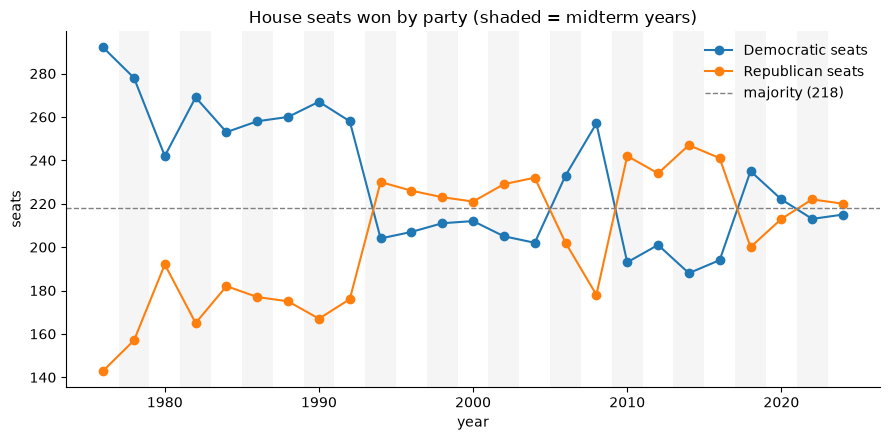

year,1976,1978,1980,1982,1984,1986,1988,1990,1992,1994,...,2006,2008,2010,2012,2014,2016,2018,2020,2022,2024
winner_party,,,,,,,,,,,,,,,,,,,,,
D,292,278,242,269,253,258,260,267,258,204,...,233,257,193,201,188,194,235,222,213,215
R,143,157,192,165,182,177,175,167,176,230,...,202,178,242,234,247,241,200,213,222,220
O,0,0,1,1,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0


In [16]:
seats = races.groupby("year")["winner_party"].value_counts().unstack(fill_value=0)
seats = seats.reindex(columns=["D", "R", "O"], fill_value=0)

fig, ax = plt.subplots()
ax.plot(seats.index, seats["D"], marker="o", label="Democratic seats")
ax.plot(seats.index, seats["R"], marker="o", label="Republican seats")
ax.axhline(218, color="gray", linestyle="--", linewidth=1, label="majority (218)")
for y in seats.index[seats.index % 4 == 2]:
    ax.axvspan(y - 1, y + 1, color="gray", alpha=0.08, linewidth=0)
ax.set(title="House seats won by party (shaded = midterm years)", xlabel="year", ylabel="seats")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "seats_by_party.png", dpi=150)
plt.show()

seats.T

## 2. Uncontested races

When one major party doesn't field a candidate, the two-party margin is exactly +1 or −1. These races carry almost no information about how competitive a district is, and they act as extreme outliers for regression.

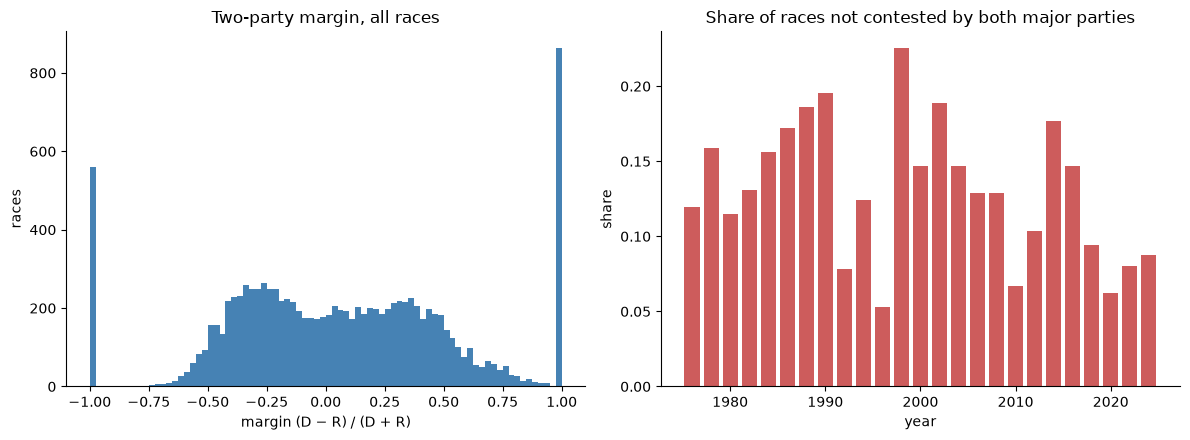

Uncontested overall: 13.1%
Uncontested in 2018: 9.4%


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(races["margin"].dropna(), bins=80, color="steelblue")
axes[0].set(title="Two-party margin, all races", xlabel="margin (D − R) / (D + R)", ylabel="races")

share = 1 - races.groupby("year")["contested"].mean()
axes[1].bar(share.index, share.values, width=1.6, color="indianred")
axes[1].set(title="Share of races not contested by both major parties", xlabel="year", ylabel="share")

fig.tight_layout(); fig.savefig(FIGS / "uncontested.png", dpi=150)
plt.show()

print(f"Uncontested overall: {1 - races['contested'].mean():.1%}")
print(f"Uncontested in 2018: {1 - races.loc[races.year == 2018, 'contested'].mean():.1%}")

**Decision for the models.** The spikes at ±1 are a large share of all races. For the *regression* task, the plan is to train on contested races only (and report this), with the LAD comparison showing what happens if they're left in. For *classification*, uncontested races stay in the data, since their winner is still a real outcome, but accuracy is also reported on competitive races only so that easy races don't inflate the score.

## 3. How predictable is a district from its last election?

This plot uses races that were contested in both the current and the previous cycle, and excludes the first election after each census (1982, 1992, 2002, 2012, 2022), when district numbers were reused for differently drawn districts.

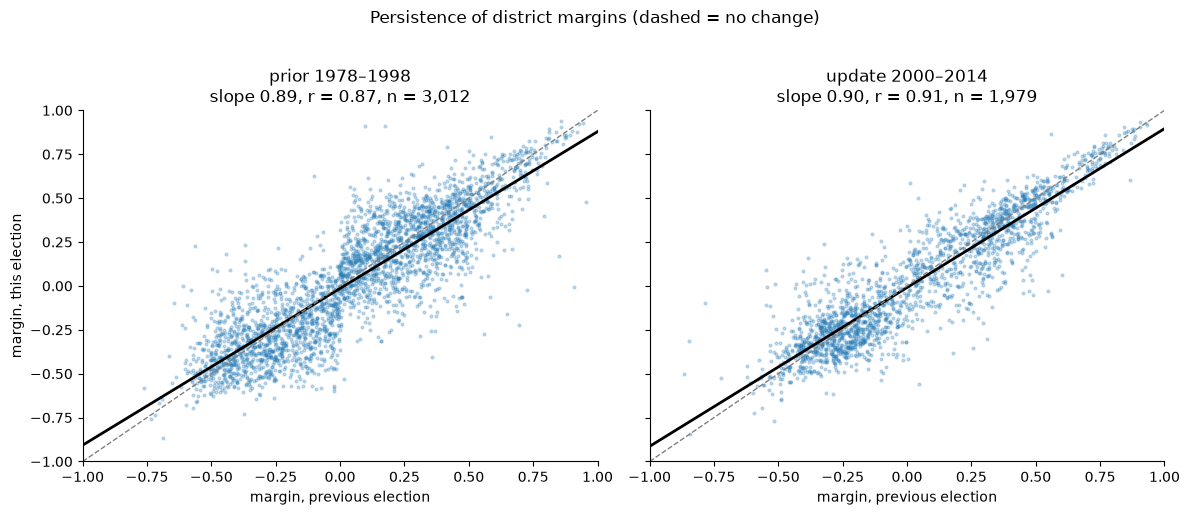

In [18]:
clean = races[
    races["contested"]
    & (races["contested_lag1"] == True)
    & (races["redistrict_year"] == 0)
    & (races["winner_party"] != "O")
].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, name in zip(axes, ["prior 1978–1998", "update 2000–2014"]):
    sub = clean[clean["period"] == name]
    slope, intercept = np.polyfit(sub["margin_lag1"], sub["margin"], 1)
    r = np.corrcoef(sub["margin_lag1"], sub["margin"])[0, 1]
    ax.scatter(sub["margin_lag1"], sub["margin"], s=4, alpha=0.25)
    xs = np.linspace(-1, 1, 50)
    ax.plot(xs, intercept + slope * xs, color="black", linewidth=2)
    ax.plot(xs, xs, color="gray", linestyle="--", linewidth=1)
    ax.set(title=f"{name}\nslope {slope:.2f}, r = {r:.2f}, n = {len(sub):,}",
           xlabel="margin, previous election", xlim=(-1, 1), ylim=(-1, 1))
axes[0].set_ylabel("margin, this election")
fig.suptitle("Persistence of district margins (dashed = no change)", y=1.02)
fig.tight_layout(); fig.savefig(FIGS / "margin_persistence.png", dpi=150, bbox_inches="tight")
plt.show()

### Has the relationship changed over time?

This is the key question for the professor's suggestion of a historical prior. If the slope and the noise around it are stable across decades, the 1978–1998 elections are a trustworthy prior for 2000–2014. If they drift, the prior should be weakened (or down-weighted).

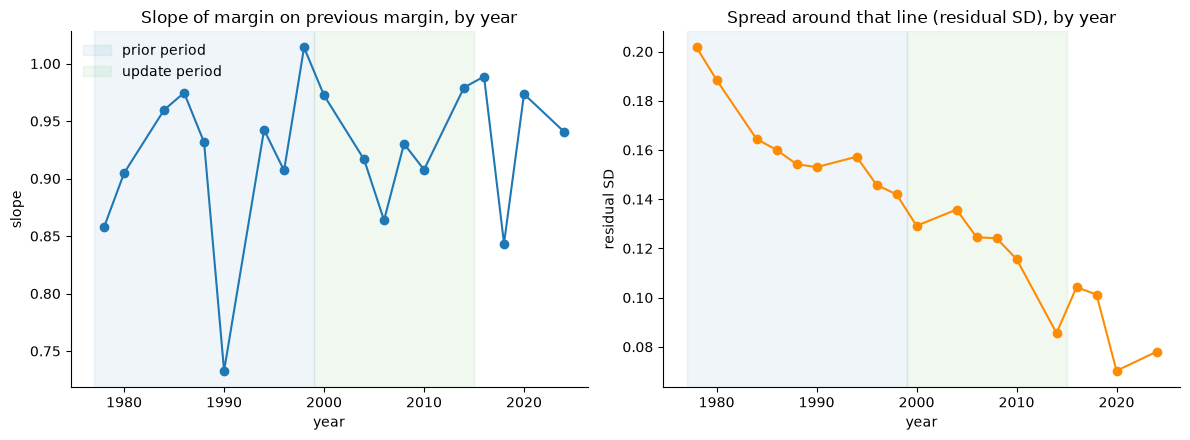

,slope,intercept,resid_sd,r,n
year,,,,,
1978,0.858,-0.022,0.202,0.822,339
1980,0.905,-0.058,0.188,0.857,339
1984,0.960,-0.074,0.164,0.886,339
1986,0.975,0.066,0.160,0.908,321
1988,0.932,-0.013,0.154,0.918,312
1990,0.733,0.035,0.153,0.878,300
1994,0.942,-0.111,0.157,0.870,366
1996,0.907,0.057,0.146,0.894,369
1998,1.014,0.000,0.142,0.922,327


In [19]:
by_year = []
for y, sub in clean.groupby("year"):
    slope, intercept = np.polyfit(sub["margin_lag1"], sub["margin"], 1)
    resid = sub["margin"] - (intercept + slope * sub["margin_lag1"])
    by_year.append({"year": y, "slope": slope, "intercept": intercept,
                    "resid_sd": resid.std(), "r": np.corrcoef(sub["margin_lag1"], sub["margin"])[0, 1],
                    "n": len(sub)})
by_year = pd.DataFrame(by_year).set_index("year")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(by_year.index, by_year["slope"], marker="o")
axes[0].set(title="Slope of margin on previous margin, by year", xlabel="year", ylabel="slope")
axes[1].plot(by_year.index, by_year["resid_sd"], marker="o", color="darkorange")
axes[1].set(title="Spread around that line (residual SD), by year", xlabel="year", ylabel="residual SD")
for ax in axes:
    ax.axvspan(1977, 1999, color="tab:blue", alpha=0.07, label="prior period")
    ax.axvspan(1999, 2015, color="tab:green", alpha=0.07, label="update period")
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "persistence_over_time.png", dpi=150)
plt.show()

by_year.round(3)

## 4. Incumbency

`incumbent` is +1 when a Democratic incumbent runs, −1 for a Republican incumbent, and 0 for an open seat (or an incumbent the name matching missed, e.g. one who switched districts after redistricting).

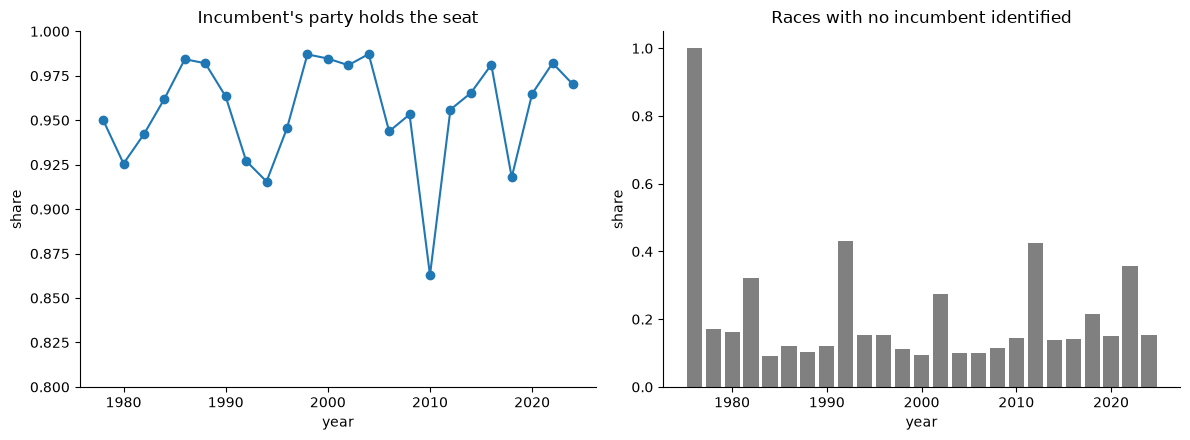

dem_win,D wins,R wins
incumbent,,
D incumbent,0.955,0.045
R incumbent,0.043,0.957
open / unknown,0.516,0.484


In [20]:
r = races[races["winner_party"] != "O"]
inc = r[r["incumbent"] != 0]
held = ((inc["incumbent"] == 1) & (inc["dem_win"] == 1)) | ((inc["incumbent"] == -1) & (inc["dem_win"] == 0))
hold_rate = held.groupby(inc["year"]).mean()
open_share = (r["incumbent"] == 0).groupby(r["year"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(hold_rate.index, hold_rate.values, marker="o")
axes[0].set(title="Incumbent's party holds the seat", xlabel="year", ylabel="share", ylim=(0.8, 1.0))
axes[1].bar(open_share.index, open_share.values, width=1.6, color="gray")
axes[1].set(title="Races with no incumbent identified", xlabel="year", ylabel="share")
fig.tight_layout(); fig.savefig(FIGS / "incumbency.png", dpi=150)
plt.show()

pd.crosstab(r["incumbent"].map({1: "D incumbent", -1: "R incumbent", 0: "open / unknown"}),
            r["dem_win"].map({1: "D wins", 0: "R wins"}), normalize="index").round(3)

## 5. The midterm penalty

For each district contested in both cycles, the swing is the change in margin from the previous election, signed so that **positive means a swing toward the president's party**. If the midterm penalty is real, midterm years should sit clearly below zero.

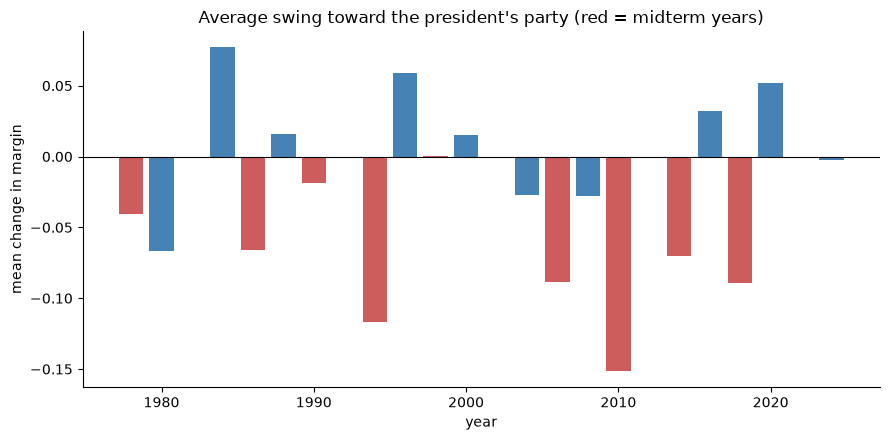

,mean,std,count
midterm,,,
midterm,-0.073,0.155,3016
presidential year,0.013,0.142,3384


In [21]:
swing = clean.assign(swing_to_pres=(clean["margin"] - clean["margin_lag1"]) * clean["pres_party"])
avg = swing.groupby("year")["swing_to_pres"].mean()
colors = ["indianred" if y % 4 == 2 else "steelblue" for y in avg.index]

fig, ax = plt.subplots()
ax.bar(avg.index, avg.values, width=1.6, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Average swing toward the president's party (red = midterm years)",
       xlabel="year", ylabel="mean change in margin")
fig.tight_layout(); fig.savefig(FIGS / "midterm_penalty.png", dpi=150)
plt.show()

swing.groupby(swing["midterm"].map({1: "midterm", 0: "presidential year"}))["swing_to_pres"].agg(["mean", "std", "count"]).round(3)

## 6. How hard is the problem?

Most districts are safe, so a model can look accurate without being useful. This section measures the class balance, how many races are competitive, and how well the naive baseline does: *the party that won the district last time wins again*.

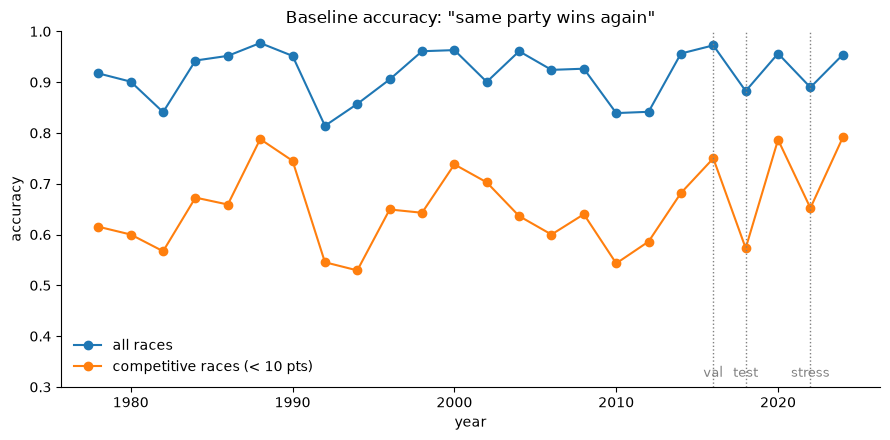

,dem_win_rate,competitive_share,baseline_acc,baseline_acc_competitive
year,,,,
2016,0.446,0.074,0.972,0.750
2018,0.539,0.205,0.882,0.573
2022,0.488,0.162,0.890,0.652


In [22]:
r = races[(races["winner_party"] != "O") & races["margin_lag1"].notna()].copy()
r["baseline_correct"] = (r["margin_lag1"] > 0).astype(int) == r["dem_win"]
r["competitive"] = r["margin"].abs() < 0.10          # decided by fewer than 10 points

summary = r.groupby("year").agg(
    dem_win_rate=("dem_win", "mean"),
    competitive_share=("competitive", "mean"),
    baseline_acc=("baseline_correct", "mean"),
)
summary["baseline_acc_competitive"] = r[r["competitive"]].groupby("year")["baseline_correct"].mean()

fig, ax = plt.subplots()
ax.plot(summary.index, summary["baseline_acc"], marker="o", label="all races")
ax.plot(summary.index, summary["baseline_acc_competitive"], marker="o", label="competitive races (< 10 pts)")
for y, label in [(VAL_YEAR, "val"), (TEST_YEAR, "test"), (STRESS_YEAR, "stress")]:
    ax.axvline(y, color="gray", linestyle=":", linewidth=1)
    ax.text(y, 0.32, label, ha="center", fontsize=9, color="gray")
ax.set(title='Baseline accuracy: "same party wins again"', xlabel="year", ylabel="accuracy", ylim=(0.3, 1.0))
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "baseline_accuracy.png", dpi=150)
plt.show()

summary.loc[[VAL_YEAR, TEST_YEAR, STRESS_YEAR]].round(3)

## 7. Prior period vs. update period at a glance

A compact comparison of the two training periods the Bayesian models will use. Large differences mean the historical prior needs to be weaker; small differences mean it can be trusted.

In [23]:
rows = {}
for name in ["prior 1978–1998", "update 2000–2014"]:
    c = clean[clean["period"] == name]
    a = races[(races["period"] == name) & (races["winner_party"] != "O")]
    i = a[a["incumbent"] != 0]
    slope, intercept = np.polyfit(c["margin_lag1"], c["margin"], 1)
    resid = c["margin"] - (intercept + slope * c["margin_lag1"])
    rows[name] = {
        "races": len(a),
        "uncontested share": 1 - a["contested"].mean(),
        "slope on margin_lag1": slope,
        "residual SD": resid.std(),
        "incumbent party holds": (((i["incumbent"] == 1) & (i["dem_win"] == 1))
                                  | ((i["incumbent"] == -1) & (i["dem_win"] == 0))).mean(),
        "seat flip rate": (((a["margin_lag1"] > 0).astype(int) != a["dem_win"]) & a["margin_lag1"].notna()).sum()
                          / a["margin_lag1"].notna().sum(),
    }
pd.DataFrame(rows).round(3)

,prior 1978–1998,update 2000–2014
races,4777.000,3476.000
uncontested share,0.145,0.136
slope on margin_lag1,0.893,0.905
residual SD,0.175,0.143
incumbent party holds,0.955,0.954
seat flip rate,0.088,0.086


## Takeaways for the modeling notebooks

*(Numbers below are from the MEDSL 1976–2024 release; rerunning the notebook regenerates every figure and table.)*

1. **The data is sane.** Every cycle has 435 races, and seat counts match the historical record.
2. **Uncontested races are about 13% of all races.** Train the regression models on contested races only; keep them for classification but also report accuracy on competitive races.
3. **The previous margin is a very strong signal.** The slope of this year's margin on last cycle's is about 0.9 in both periods, so districts keep roughly 90% of their lean from one election to the next.
4. **The relationship is stable, but the noise has shrunk.** The slope barely changes between the prior period (0.89) and the update period (0.91), and incumbents' parties held about 95.5% of seats in both. But the spread around the line fell from about 0.20 in 1978 to under 0.10 in recent cycles: House results have become much more predictable from past results. **Implication for the Bayesian models:** the 1978–1998 prior is a good guide to the *coefficients*, but it overstates the *noise level*, so the noise variance should be estimated from recent data (or given a weak prior) rather than copied from the prior period.
5. **The midterm penalty is clearly visible.** In midterm years, districts swung on average about 7 points away from the president's party, versus a slight swing toward it in presidential years. The `midterm_x_pres` feature should matter.
6. **Accuracy will flatter every model.** The "same party wins again" baseline gets 88% of 2018 races right but only about 57% of races decided by fewer than 10 points. Those competitive races (about 20% of 2018) are where the models need to earn their keep.
